# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Muhammad Azka Ananta Khairon | 5054251004 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score

In [3]:
df = pd.read_csv("/content/Mall_Customers.csv")
display(df.head())

print()
print(f"Jumlah Baris : {df.shape[0]}")
print(f"Jumlah Kolom : {df.shape[1]}")

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Jumlah Baris : 200
Jumlah Kolom : 5


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [5]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [6]:
print(f"Jumlah data duplikat: {df.duplicated().sum()}")
df.isna().sum()[df.isna().sum()>0]

Jumlah data duplikat: 0


,0


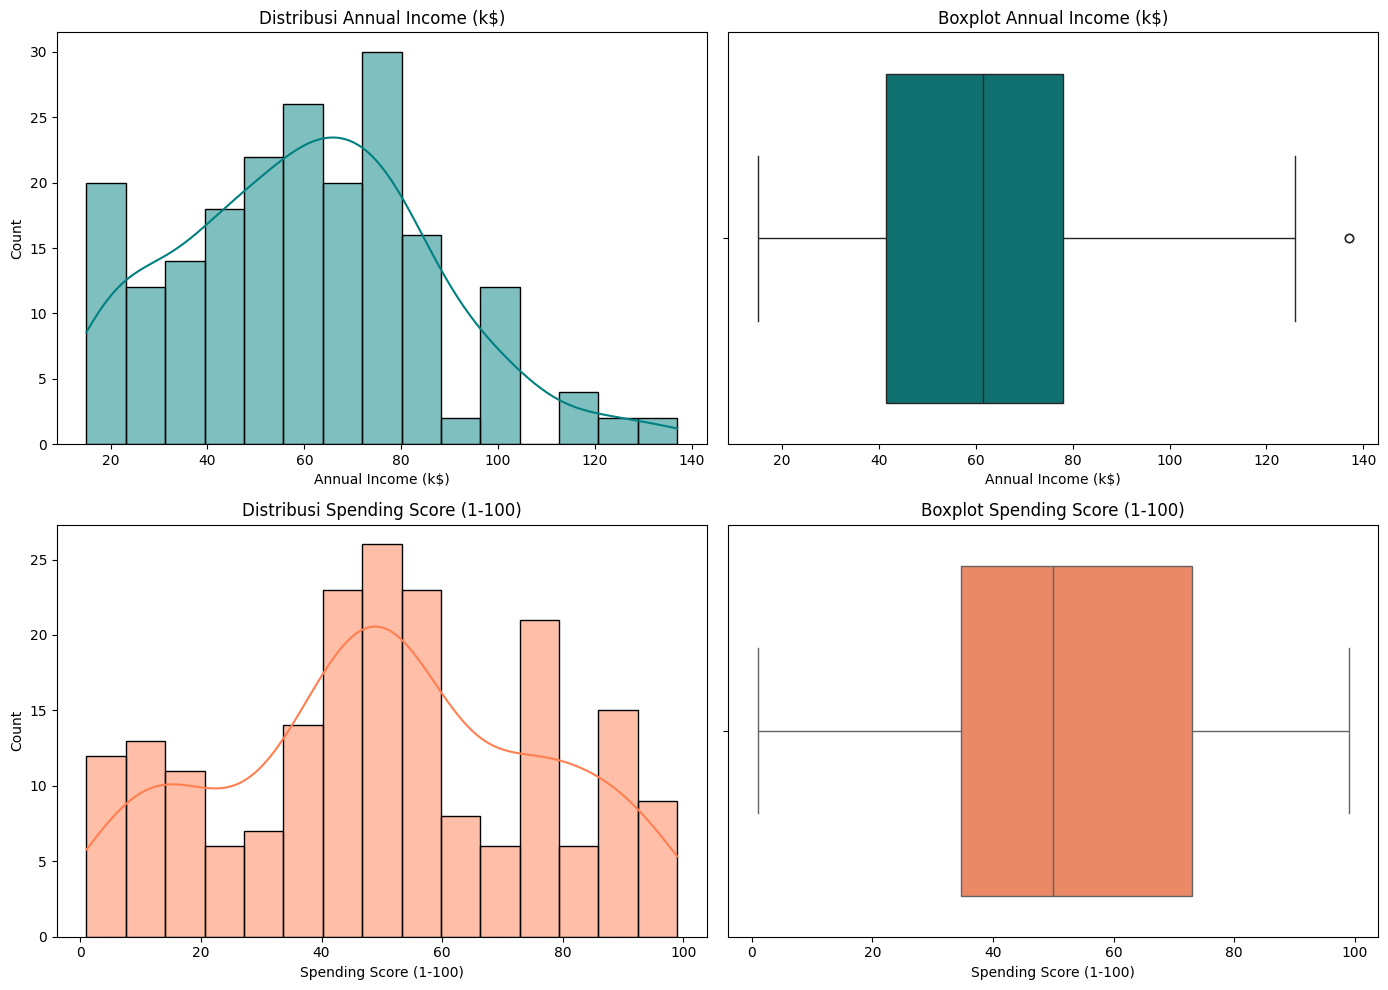

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(
    data=df,
    x="Annual Income (k$)",
    kde=True,
    ax=axes[0, 0],
    color="teal",
    bins=15,
)
axes[0, 0].set_title("Distribusi Annual Income (k$)", fontsize=12)

sns.boxplot(data=df, x="Annual Income (k$)", ax=axes[0, 1], color="teal")
axes[0, 1].set_title("Boxplot Annual Income (k$)", fontsize=12)

sns.histplot(
    data=df,
    x="Spending Score (1-100)",
    kde=True,
    ax=axes[1, 0],
    color="coral",
    bins=15,
)
axes[1, 0].set_title("Distribusi Spending Score (1-100)", fontsize=12)

sns.boxplot(data=df, x="Spending Score (1-100)", ax=axes[1, 1], color="coral")
axes[1, 1].set_title("Boxplot Spending Score (1-100)", fontsize=12)

plt.tight_layout()
plt.show()

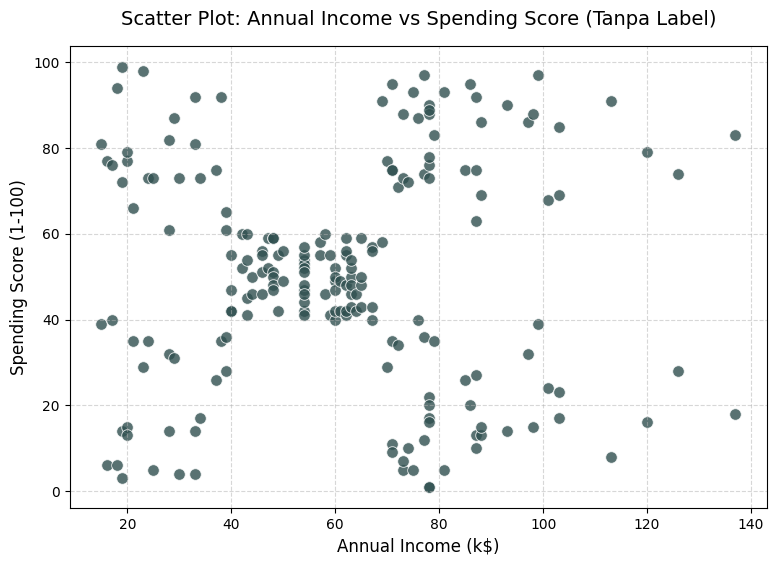

In [8]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    s=70,
    color="darkslategrey",
    alpha=0.8,
)

plt.title(
    "Scatter Plot: Annual Income vs Spending Score (Tanpa Label)",
    fontsize=14,
    pad=15,
)
plt.xlabel("Annual Income (k$)", fontsize=12)
plt.ylabel("Spending Score (1-100)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()


## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

### Jawaban Pertanyaan EDA

1. Missing Value & Baris Duplikat:
   - Missing Value: Tidak ada missing value
   - Baris Duplikat: Tidak ada baris duplikat

2. Rentang Pendapatan & Spending Score:
   - Annual Income (k$): Berada pada rentang sekitar 15k hingga 137k. Distribusinya cenderung sedikit right-skewed dengan nilai terbanyak di kisaran 50k–80k. Terdapat 1 potensi outlier di atas 130k.
   - Spending Score (1–100): Berada pada rentang sekitar 1 hingga 99. Distribusi tersebar relatif luas dengan konsentrasi padat pada nilai tengah (skor 40–60) serta tidak memiliki outlier.

3. Pemisahan Kelompok (Visual Cluster):
   - Ya, kedua fitur menunjukkan pemisahan kelompok yang cukup jelas. Pada scatter plot, terlihat ada 5 kelompok:
     1. Pendapatan Rendah – Spending Score Tinggi (Kiri Atas)
     2. Pendapatan Rendah – Spending Score Rendah (Kiri Bawah)
     3. Pendapatan Sedang – Spending Score Sedang (Tengah/Pusat Data)
     4. Pendapatan Tinggi – Spending Score Tinggi (Kanan Atas)
     5. Pendapatan Tinggi – Spending Score Rendah (Kanan Bawah)

# 2. Preprocessing

In [10]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].copy()

print(X.shape)
display(X.head())

(200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [11]:
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns)

display(X_scaled.head())

print()
display(X_scaled.describe())

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


,Annual Income (k$),Spending Score (1-100)
count,2.000000e+02,2.000000e+02
mean,-2.131628e-16,-1.465494e-16
std,1.002509e+00,1.002509e+00
min,-1.738999e+00,-1.910021e+00
25%,-7.275093e-01,-5.997931e-01
50%,3.587926e-02,-7.764312e-03
75%,6.656748e-01,8.851316e-01
max,2.917671e+00,1.894492e+00


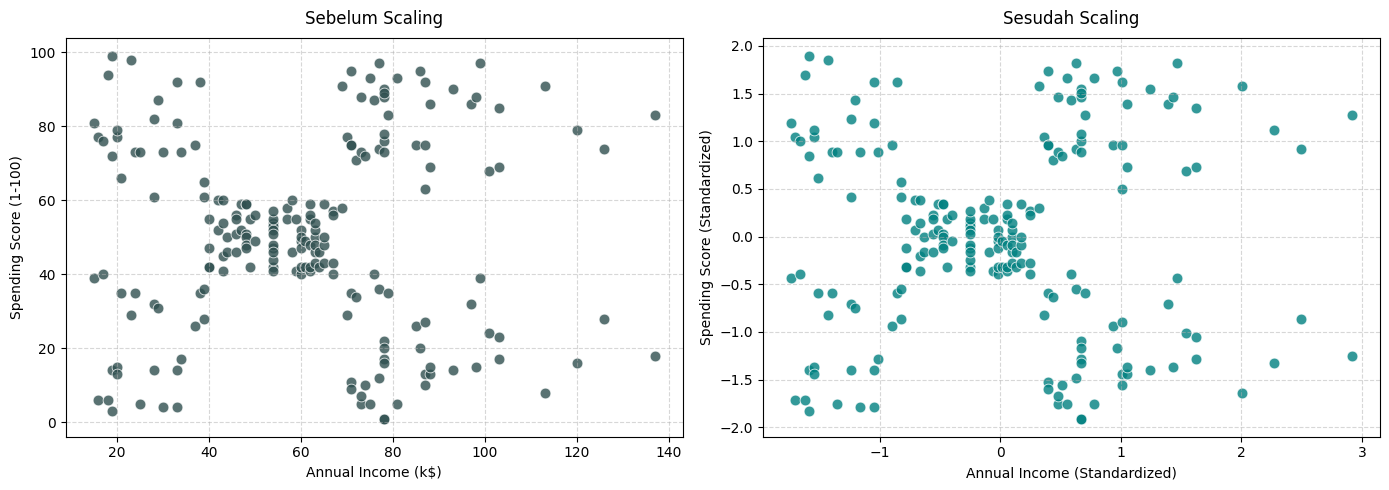

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=X,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    ax=axes[0],
    color="darkslategrey",
    s=60,
    alpha=0.8,
)
axes[0].set_title(
    "Sebelum Scaling", fontsize=12, pad=10
)
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")
axes[0].grid(True, linestyle="--", alpha=0.5)

sns.scatterplot(
    data=X_scaled,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    ax=axes[1],
    color="teal",
    s=60,
    alpha=0.8,
)
axes[1].set_title(
    "Sesudah Scaling", fontsize=12, pad=10
)
axes[1].set_xlabel("Annual Income (Standardized)")
axes[1].set_ylabel("Spending Score (Standardized)")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Pentingnya Feature Scaling pada Clustering

1. Sensitivitas Perhitungan Jarak (DBSCAN & BIRCH):
   Algoritma berbasis jarak seperti DBSCAN dan BIRCH sangat sensitif terhadap rentang skala antar fitur. Tanpa scaling, fitur dengan rentang nilai yang lebih besar atau varians yang tinggi dapat mendominasi perhitungan jarak Euclidean, sehingga fitur dengan rentang kecil diabaikan.
   
2. Asumsi Distribusi Gaussian (GMM/EM):
   GMM berasumsi bahwa data berasal dari campuran distribusi Gaussian. Memelintir atau menyelaraskan skala fitur membantu matriks kovarians pada GMM agar tidak terkondisi buruk (ill-conditioned matrix) saat proses estimasi parameternya.

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

### Alasan Pemilihan Fitur dan Pengabaian CustomerID

Pemilihan fitur Annual Income (k$) dan Spending Score (1-100) didasarkan pada relevansi langsung keduanya dalam memetakan segmentasi perilaku belanja pelanggan, di mana kombinasi pendapatan dan daya beli ini secara visual serta analitis terbukti mampu membentuk kluster yang terpisah dengan jelas. Sebaliknya, CustomerID tidak digunakan karena hanya berfungsi sebagai identifier yang tidak memiliki makna matematis maupun kontribusi informasi terhadap pola segmentasi, sehingga memasukkannya hanya akan menambah noise. Sementara itu, fitur Gender dan Age diabaikan pada eksperimen utama ini agar analisis tetap fokus pada ruang 2D yang intuitif dan mudah divisualisasikan, meskipun kedua fitur tersebut tetap dapat dimanfaatkan nantinya untuk profiling atau interpretasi demografis tambahan setelah model pembagian kluster terbentuk.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [13]:
eps_init = 0.3
min_samples_init = 5

dbscan_base = DBSCAN(eps=eps_init, min_samples=min_samples_init)
labels_dbscan = dbscan_base.fit_predict(X_scaled)

In [17]:
label_counts = pd.Series(labels_dbscan).value_counts().sort_index()

n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)

n_noise_dbscan = list(labels_dbscan).count(-1)

print("Hasil Clustering DBSCAN Baseline")
print(f"Parameter: eps={eps_init}, min_samples={min_samples_init}")
print(f"Jumlah Cluster Terbentuk : {n_clusters_dbscan}")
print(f"Jumlah Data Noise (-1)   : {n_noise_dbscan}")
print()
print("Distribusi Anggota per Label:")
for label, count in label_counts.items():
    if label == -1:
        print(f"  Label {label} (Noise)  : {count} data")
    else:
        print(f"  Label  {label}          : {count} data")

Hasil Clustering DBSCAN Baseline
Parameter: eps=0.3, min_samples=5
Jumlah Cluster Terbentuk : 7
Jumlah Data Noise (-1)   : 35

Distribusi Anggota per Label:
  Label -1 (Noise)  : 35 data
  Label  0          : 12 data
  Label  1          : 5 data
  Label  2          : 7 data
  Label  3          : 88 data
  Label  4          : 30 data
  Label  5          : 14 data
  Label  6          : 9 data


/tmp/ipykernel_3187/1797092424.py:22: UserWarning: You passed a edgecolor/edgecolors ('none') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(


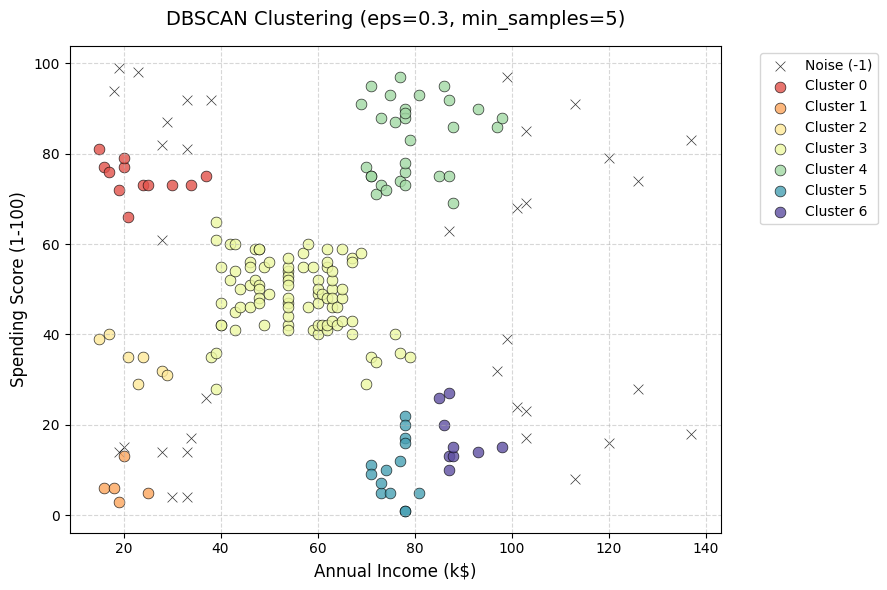

In [15]:
plt.figure(figsize=(9, 6))

unique_labels = sorted(set(labels_dbscan))
colors = [
    plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))
]

for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]
        marker = "x"
        label_name = "Noise (-1)"
        size = 50
    else:
        marker = "o"
        label_name = f"Cluster {k}"
        size = 60

    class_member_mask = labels_dbscan == k
    xy = X[class_member_mask]

    plt.scatter(
        xy["Annual Income (k$)"],
        xy["Spending Score (1-100)"],
        s=size,
        c=[col],
        marker=marker,
        label=label_name,
        alpha=0.8,
        edgecolors="none" if k == -1 else "k",
        linewidths=0.5,
    )

plt.title(
    f"DBSCAN Clustering (eps={eps_init}, min_samples={min_samples_init})",
    fontsize=14,
    pad=15,
)
plt.xlabel("Annual Income (k$)", fontsize=12)
plt.ylabel("Spending Score (1-100)", fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [19]:
eps_values = [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]
min_samples_values = [3, 4, 5, 6, 7]

results_dbscan = []

for eps in eps_values:
    for min_samples in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=min_samples)
        labels = db.fit_predict(X_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        if n_clusters > 1 and len(set(labels)) < len(X_scaled):
            non_noise_mask = labels != -1
            if len(set(labels[non_noise_mask])) > 1:
                sil_score = silhouette_score(
                    X_scaled[non_noise_mask], labels[non_noise_mask]
                )
            else:
                sil_score = np.nan
        else:
            sil_score = np.nan

        results_dbscan.append(
            {
                "eps": eps,
                "min_samples": min_samples,
                "n_clusters": n_clusters,
                "n_noise": n_noise,
                "silhouette_score": sil_score,
            }
        )

df_dbscan_results = pd.DataFrame(results_dbscan)

print("Ringkasan Eksperimen Hyperparameter Tuning DBSCAN")
display(
    df_dbscan_results.sort_values(
        by="silhouette_score", ascending=False
    ).reset_index(drop=True)
)

Ringkasan Eksperimen Hyperparameter Tuning DBSCAN


,eps,min_samples,n_clusters,n_noise,silhouette_score
0,0.30,7,4,72,0.645159
1,0.20,4,5,73,0.617282
2,0.20,6,4,95,0.613836
3,0.20,7,4,100,0.609411
4,0.25,7,5,77,0.594452
5,0.20,5,7,77,0.585613
6,0.35,7,5,47,0.570781
7,0.25,6,6,69,0.562294
8,0.35,5,6,23,0.557746
9,0.25,4,7,43,0.537969


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

### Analisis Hasil Eksperimen DBSCAN

Berdasarkan tabel eksperimen hyperparameter tuning DBSCAN yang telah dilakukan, diperoleh beberapa poin pengamatan penting:

1. Pengaruh Kenaikan eps:
   Semakin besar nilai eps, jumlah data yang ditandai sebagai noise semakin berkurang. Hal ini terjadi karena jangkauan radius pencarian tetangga semakin luas, sehingga lebih banyak titik data yang memenuhi kriteria kepadatan. Kenaikan eps cenderung menggabungkan cluster-cluster berdekatan menjadi satu cluster besar. Misalnya pada eps = 0.50, jumlah cluster menyusut hingga tersisa 2 cluster saja karena batasan antar cluster yang terpisah mulai mengabur akibat radius pencarian yang terlalu besar.

2. Pengaruh min_samples:
   Semakin tinggi nilai min_samples, syarat minimum titik untuk dianggap sebagai core point menjadi lebih ketat. Menaikkan min_samples pada nilai eps yang sama akan meningkatkan jumlah noise. Sebaliknya, nilai min_samples yang lebih kecil (seperti 3 atau 4) membuat algoritma lebih sensitif dalam membentuk cluster-cluster kecil tetapi menyatukan titik-titik yang seharusnya terpisah.

3. Kombinasi Parameter Ekstrem (Over-grouping vs Over-noise):
   - Terlalu Banyak Noise (Over-filtering): Terjadi pada nilai eps kecil (eps = 0.20), di mana jumlah noise melonjak tinggi hingga mencapai 73 hingga 95 titik noise (hampir separuh dari total dataset).
   - Satu Cluster Besar / Menggabungkan Banyak Cluster (Over-merging): Terjadi pada nilai eps tinggi (eps = 0.45 dan eps = 0.50), di mana data hanya terbagi menjadi 2 cluster saja, padahal pola visual data pada tahap EDA secara jelas menunjukkan 5 kelompok terpisah.
   - Kombinasi Optimal: Parameter eps = 0.30 dan min_samples = 7 menghasilkan 4 cluster dengan 47 noise dan memberikan nilai Silhouette Score tertinggi (0.645). Namun, jika prioritasnya adalah menangkap 5 pola kelompok yang terlihat di EDA, eps = 0.30 dan min_samples = 4 membentuk 5 cluster dengan 23 noise (Silhouette Score: 0.519).

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [21]:
threshold_init = 0.5
n_clusters_init = 5

birch_base = Birch(threshold=threshold_init, n_clusters=n_clusters_init)
labels_birch = birch_base.fit_predict(X_scaled)

In [22]:
label_counts_birch = pd.Series(labels_birch).value_counts().sort_index()

n_clusters_birch = len(set(labels_birch))

print("Hasil Clustering BIRCH Baseline")
print(f"Parameter: threshold={threshold_init}, n_clusters={n_clusters_init}")
print(f"Jumlah Cluster Terbentuk : {n_clusters_birch}")
print()
print("Distribusi Anggota per Cluster:")
for label, count in label_counts_birch.items():
    print(f"  Cluster {label} : {count} data")

Hasil Clustering BIRCH Baseline
Parameter: threshold=0.5, n_clusters=5
Jumlah Cluster Terbentuk : 5

Distribusi Anggota per Cluster:
  Cluster 0 : 36 data
  Cluster 1 : 109 data
  Cluster 2 : 8 data
  Cluster 3 : 25 data
  Cluster 4 : 22 data


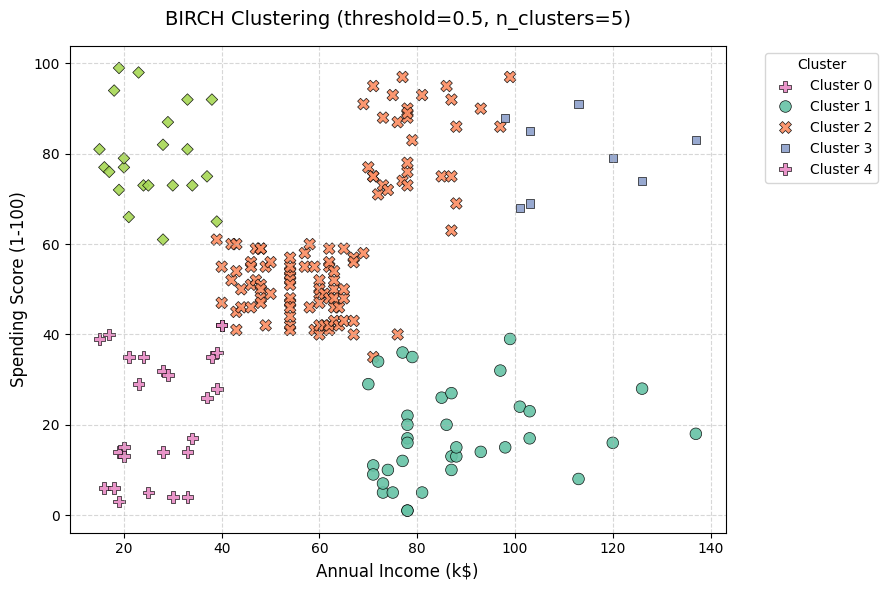

In [23]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=X,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue=labels_birch,
    palette="Set2",
    style=labels_birch,
    s=70,
    alpha=0.9,
    edgecolor="k",
    linewidth=0.5,
)

plt.title(
    f"BIRCH Clustering (threshold={threshold_init}, n_clusters={n_clusters_init})",
    fontsize=14,
    pad=15,
)
plt.xlabel("Annual Income (k$)", fontsize=12)
plt.ylabel("Spending Score (1-100)", fontsize=12)
plt.legend(
    title="Cluster",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    labels=[f"Cluster {i}" for i in sorted(set(labels_birch))],
)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [25]:
threshold_values = [0.2, 0.3, 0.5, 0.7, 1.0, 1.2, 1.5]
target_n_clusters = 5

results_birch = []

for th in threshold_values:
    birch_model = Birch(threshold=th, n_clusters=target_n_clusters)
    labels = birch_model.fit_predict(X_scaled)

    n_clusters = len(set(labels))

    if n_clusters > 1:
        sil_score = silhouette_score(X_scaled, labels)
    else:
        sil_score = np.nan

    results_birch.append(
        {
            "threshold": th,
            "n_clusters": n_clusters,
            "silhouette_score": sil_score,
        }
    )

df_birch_results = pd.DataFrame(results_birch)

print("Ringkasan Eksperimen Threshold BIRCH")
display(df_birch_results)

Ringkasan Eksperimen Threshold BIRCH


/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_birch.py:727: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_birch.py:727: ConvergenceWarning: Number of subclusters found (1) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


,threshold,n_clusters,silhouette_score
0,0.2,5,0.553809
1,0.3,5,0.478062
2,0.5,5,0.414450
3,0.7,5,0.420676
4,1.0,4,0.388557
5,1.2,5,0.352564
6,1.5,1,NaN


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

### Analisis Hasil Eksperimen BIRCH

Berdasarkan tabel eksperimen dan visualisasi hasil clustering BIRCH, berikut analisis pengamatannya:

1. Pengaruh Peningkatan threshold:
   Ketika threshold diperbesar, jari-jari subcluster meluas sehingga lebih banyak titik dimasukkan ke dalam satu subcluster yang sama. Akibatnya, jumlah cluster akhir cenderung menyusut (misalnya pada threshold = 1.0 menjadi 4 cluster, dan pada threshold = 1.5 menyatu sepenuhnya menjadi 1 cluster). Pada nilai threshold = 0.2 (dengan n_clusters = 5), diperoleh Silhouette Score tertinggi (0.5538), menunjukkan batas subcluster yang lebih presisi sebelum pengelompokan akhir.

2. Perbedaan BIRCH dan DBSCAN dalam Menangani Outlier/Noise
   - DBSCAN: Menggunakan konsep kepadatan (density-based), sehingga titik-titik yang berada jauh atau di area berkepadatan rendah secara eksplisit ditandai sebagai noise/outlier (label -1).
   - BIRCH: Secara default, BIRCH memaksa setiap titik data untuk masuk ke dalam salah satu cluster (tidak memiliki mekanisme eksplisit untuk membuang titik sebagai noise). Seperti yang terlihat pada plot (misalnya Cluster 3 dan Cluster 1 di area income tinggi), titik-titik ekstrim yang jauh dari pusat tetap ditarik masuk ke cluster terdekat, yang dapat mendistorsi batas cluster.

3. Pengaruh Parameter n_clusters:
   Ya, hasil akhir sangat dipengaruhi oleh parameter n_clusters. Jika n_clusters ditentukan (misalnya n_clusters = 5), BIRCH akan melakukan langkah global clustering sekunder (menggunakan algoritma Agglomerative Clustering) untuk menggabungkan sub-subcluster pada pohon CF menjadi tepat 5 cluster akhir. Jika n_clusters diatur ke None, jumlah cluster akhir murni ditentukan oleh berapa banyak subcluster yang terbentuk dari batas threshold.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [27]:
n_components_init = 5
covariance_type_init = "full"
random_state_init = 42

gmm_base = GaussianMixture(
    n_components=n_components_init,
    covariance_type=covariance_type_init,
    random_state=random_state_init,
)
labels_gmm = gmm_base.fit_predict(X_scaled)

In [28]:
label_counts_gmm = pd.Series(labels_gmm).value_counts().sort_index()

print("Hasil Clustering GMM Baseline")
print(
    f"Parameter: n_components={n_components_init}, covariance_type='{covariance_type_init}'"
)
print(f"Jumlah Cluster Terbentuk : {len(label_counts_gmm)}\n")
print("Distribusi Anggota per Cluster:")
for label, count in label_counts_gmm.items():
    print(f"  Cluster {label} : {count} data")

gmm_probs = gmm_base.predict_proba(X_scaled)
df_probs = pd.DataFrame(
    gmm_probs, columns=[f"Prob_Cluster_{i}" for i in range(n_components_init)]
)
df_probs["Assigned_Cluster"] = labels_gmm
df_probs["Max_Prob"] = df_probs.drop(columns=["Assigned_Cluster"]).max(axis=1)

print()
print("5 Baris Pertama Probabilitas Keanggotaan (predict_proba)")
display(df_probs.head())

print()
print("5 Data dengan Keanggotaan Paling Tidak Pasti (Uncertainity Tinggi")
display(df_probs.sort_values(by="Max_Prob", ascending=True).head())

Hasil Clustering GMM Baseline
Parameter: n_components=5, covariance_type='full'
Jumlah Cluster Terbentuk : 5

Distribusi Anggota per Cluster:
  Cluster 0 : 84 data
  Cluster 1 : 39 data
  Cluster 2 : 21 data
  Cluster 3 : 33 data
  Cluster 4 : 23 data

5 Baris Pertama Probabilitas Keanggotaan (predict_proba)


,Prob_Cluster_0,Prob_Cluster_1,Prob_Cluster_2,Prob_Cluster_3,Prob_Cluster_4,Assigned_Cluster,Max_Prob
0,1.576897e-05,1.880092e-08,9.520312e-04,5.200131e-08,0.999032,4,0.999032
1,1.627762e-05,1.895968e-04,9.997902e-01,4.210134e-23,0.000004,2,0.999790
2,2.213394e-19,9.526157e-19,1.225495e-12,1.862233e-04,0.999814,4,0.999814
3,1.054448e-04,1.800877e-04,9.996937e-01,3.793901e-21,0.000021,2,0.999694
4,6.473014e-05,3.842732e-08,1.556695e-03,4.757227e-08,0.998378,4,0.998378



5 Data dengan Keanggotaan Paling Tidak Pasti (Uncertainity Tinggi


,Prob_Cluster_0,Prob_Cluster_1,Prob_Cluster_2,Prob_Cluster_3,Prob_Cluster_4,Assigned_Cluster,Max_Prob
124,0.497063,4.020399e-07,5.610367e-14,5.029323e-01,4.143026e-06,3,0.502932
48,0.611381,4.208143e-06,2.609859e-04,6.865689e-06,3.883471e-01,0,0.611381
49,0.611381,4.208143e-06,2.609859e-04,6.865689e-06,3.883471e-01,0,0.611381
27,0.278521,4.886785e-04,6.746109e-01,1.610322e-12,4.637931e-02,2,0.674611
160,0.772053,1.625129e-05,1.301359e-16,2.279312e-01,6.913927e-09,0,0.772053


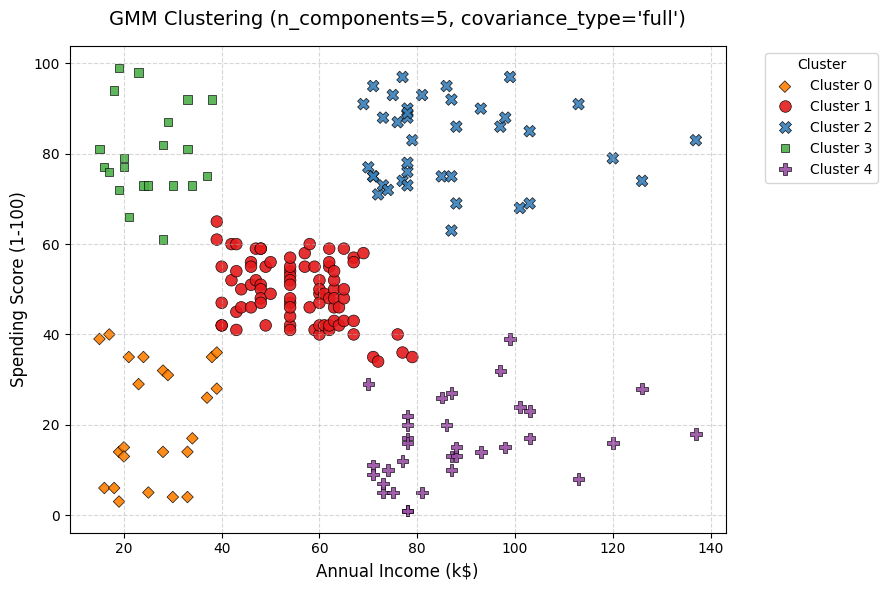

In [29]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=X,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue=labels_gmm,
    palette="Set1",
    style=labels_gmm,
    s=70,
    alpha=0.9,
    edgecolor="k",
    linewidth=0.5,
)

plt.title(
    f"GMM Clustering (n_components={n_components_init}, covariance_type='{covariance_type_init}')",
    fontsize=14,
    pad=15,
)
plt.xlabel("Annual Income (k$)", fontsize=12)
plt.ylabel("Spending Score (1-100)", fontsize=12)
plt.legend(
    title="Cluster",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    labels=[f"Cluster {i}" for i in sorted(set(labels_gmm))],
)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Ringkasan Evaluasi GMM


,n_components,bic,silhouette_score
0,2,1153.904655,0.379082
1,3,1151.718274,0.430190
2,4,1103.790149,0.413392
3,5,1058.652252,0.553689
4,6,1074.682807,0.516982
5,7,1087.328517,0.509057
6,8,1102.370701,0.430210


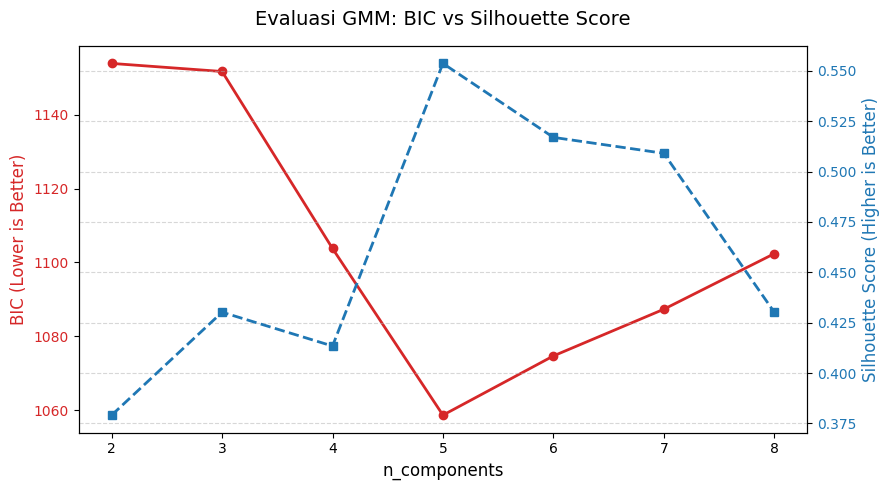

In [30]:
components_range = range(2, 9)

results_gmm = []

for n in components_range:
    gmm = GaussianMixture(
        n_components=n, covariance_type="full", random_state=42
    )
    labels = gmm.fit_predict(X_scaled)

    bic = gmm.bic(X_scaled)
    sil_score = silhouette_score(X_scaled, labels)

    results_gmm.append(
        {"n_components": n, "bic": bic, "silhouette_score": sil_score}
    )

df_gmm_results = pd.DataFrame(results_gmm)

print("Ringkasan Evaluasi GMM")
display(df_gmm_results)

fig, ax1 = plt.subplots(figsize=(9, 5))

color = "tab:red"
ax1.set_xlabel("n_components", fontsize=12)
ax1.set_ylabel("BIC (Lower is Better)", color=color, fontsize=12)
ax1.plot(
    df_gmm_results["n_components"],
    df_gmm_results["bic"],
    color=color,
    marker="o",
    linewidth=2,
)
ax1.tick_params(axis="y", labelcolor=color)

ax2 = ax1.twinx()
color = "tab:blue"
ax2.set_ylabel("Silhouette Score (Higher is Better)", color=color, fontsize=12)
ax2.plot(
    df_gmm_results["n_components"],
    df_gmm_results["silhouette_score"],
    color=color,
    marker="s",
    linestyle="--",
    linewidth=2,
)
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Evaluasi GMM: BIC vs Silhouette Score", fontsize=14, pad=15)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

### Analisis Hasil Eksperimen EM / GMM

Berdasarkan hasil eksekusi dan grafik evaluasi GMM, berikut adalah analisis pengamatannya:

1. Arti Probabilitas Keanggotaan (Soft Clustering):
   Berbeda dengan DBSCAN atau BIRCH yang memberikan keanggotaan mutlak (hard clustering), GMM menghasilkan probabilitas posterior untuk setiap data terhadap seluruh cluster.Sebagian besar data memiliki keanggotaan yang sangat tegas (probabilitas $\approx 1.0$). Namun, untuk data yang terletak di perbatasan antar kelompok (seperti data index 124 dengan Max_Prob $\approx 0.502$), GMM menunjukkan ketidakpastian (uncertainty) di mana data tersebut berpeluang hampir seimbang untuk masuk ke Cluster 0 (49.7%) maupun Cluster 3 (50.3%).

2. Pengaruh Perubahan n_components:
    Mengubah n_components menentukan berapa jumlah distribusi Gaussian yang dicocokkan ke dalam data. Jika terlalu kecil (n=2 atau 3), distribusi akan dipaksa menggabungkan kelompok-kelompok yang terpisah. Jika terlalu besar (n=8), distribusi Gaussian akan memecah kelompok alami data menjadi sub-bagian kecil (membawa risiko overfitting).

3. Alasan n_components Harus Ditentukan Sebelum Pelatihan:
   GMM menggunakan algoritma Expectation-Maximization (EM) yang bekerja secara parametrik probabilistik. Algoritma ini membutuhkan penetapan awal jumlah komponen (K) untuk menginisialisasi parameter distribusi (nilai mean $\mu_k$, matriks kovarians $\Sigma_k$, dan bobot campuran $\pi_k$). Tanpa penentuan K awal, ruang parameter untuk fungsi log-likelihood tidak memiliki batasan dimensi.

4. Kesesuaian Silhouette Score Tertinggi dengan BIC Terendah:
   Ya, pada eksperimen ini model dengan Silhouette Score tertinggi juga memiliki nilai BIC terendah. Berdasarkan tabel dan grafik evaluasi, pada n_components = 5, diperoleh Silhouette Score tertinggi (0.5537) sekaligus nilai BIC terendah (1058.65). Hal ini mengonfirmasi bahwa 5 cluster adalah jumlah komponen paling optimal yang menyeimbangkan antara kerapatan cluster (separation/cohesion) dan kompleksitas model (goodness of fit tanpa overfitting).

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [31]:
def evaluate_clustering(X_data, labels, model_name="Model"):
    labels = np.array(labels)

    non_noise_mask = labels != -1
    n_noise = list(labels).count(-1)

    X_eval = X_data[non_noise_mask]
    labels_eval = labels[non_noise_mask]

    n_clusters = len(set(labels_eval))

    if n_clusters >= 2 and len(labels_eval) > n_clusters:
        sil = silhouette_score(X_eval, labels_eval)
        db = davies_bouldin_score(X_eval, labels_eval)
        ch = calinski_harabasz_score(X_eval, labels_eval)
    else:
        sil, db, ch = np.nan, np.nan, np.nan

    return {
        "Model": model_name,
        "Jumlah Cluster": n_clusters,
        "Jumlah Noise": n_noise,
        "Silhouette Score": sil,
        "Davies-Bouldin Index": db,
        "Calinski-Harabasz Index": ch,
    }

In [32]:
db_best = DBSCAN(eps=0.3, min_samples=4).fit(X_scaled)
labels_dbscan_best = db_best.labels_

birch_best = Birch(threshold=0.2, n_clusters=5).fit(X_scaled)
labels_birch_best = birch_best.labels_

gmm_best = GaussianMixture(
    n_components=5, covariance_type="full", random_state=42
).fit(X_scaled)
labels_gmm_best = gmm_best.predict(X_scaled)

eval_dbscan = evaluate_clustering(
    X_scaled.values, labels_dbscan_best, "DBSCAN (eps=0.3, min_s=4)"
)
eval_birch = evaluate_clustering(
    X_scaled.values, labels_birch_best, "BIRCH (th=0.2, k=5)"
)
eval_gmm = evaluate_clustering(
    X_scaled.values, labels_gmm_best, "GMM (EM) (k=5)"
)

df_comparison = pd.DataFrame([eval_dbscan, eval_birch, eval_gmm])

print("Tabel Perbandingan Metrik Evaluasi Clustering")
display(df_comparison)

Tabel Perbandingan Metrik Evaluasi Clustering


,Model,Jumlah Cluster,Jumlah Noise,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,"DBSCAN (eps=0.3, min_s=4)",8,23,0.519746,0.610272,185.796505
1,"BIRCH (th=0.2, k=5)",5,0,0.553809,0.577862,244.410326
2,GMM (EM) (k=5),5,0,0.553689,0.576010,244.940197


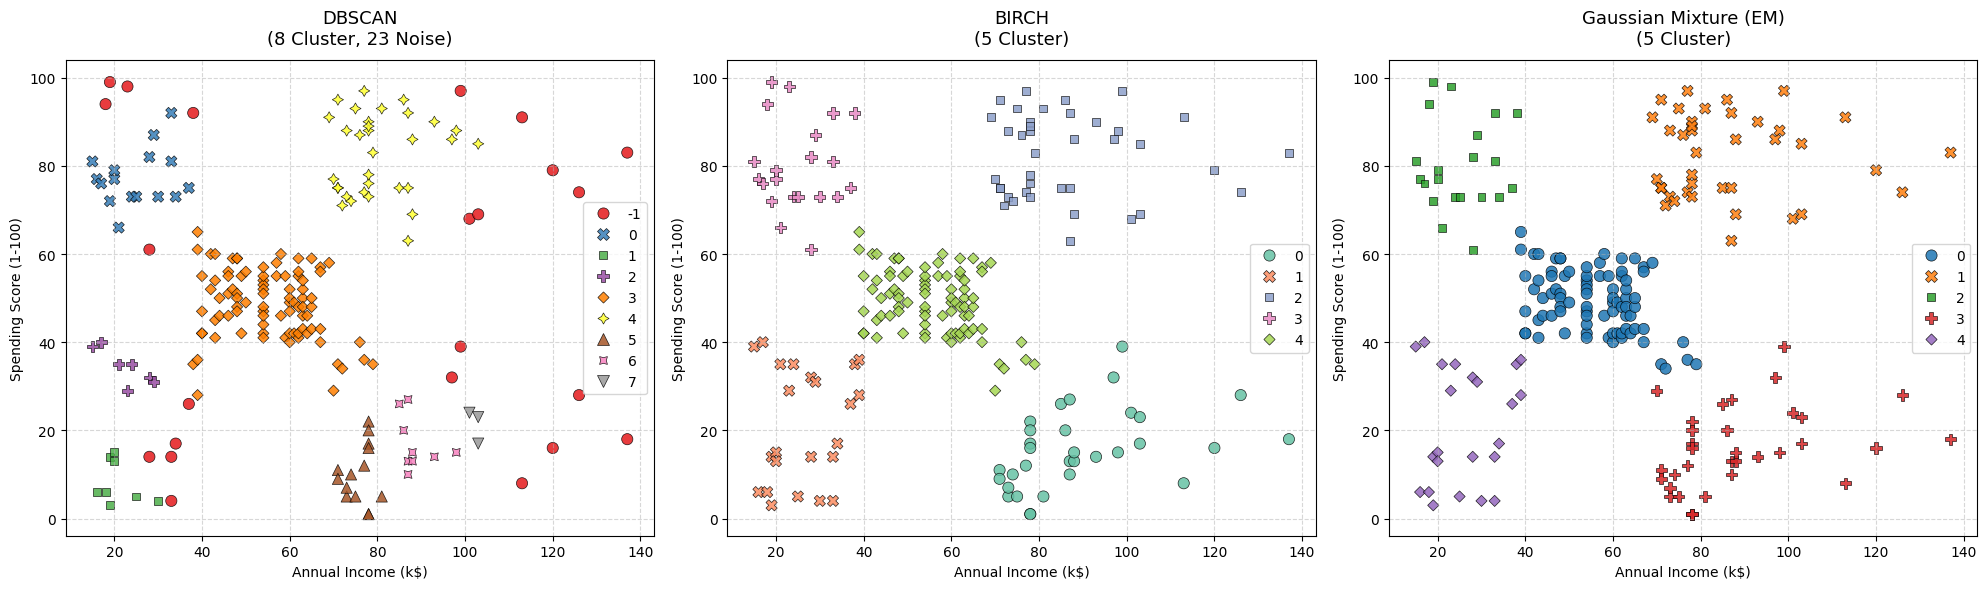

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

models_info = [
    (
        labels_dbscan_best,
        (
            f"DBSCAN\n({eval_dbscan['Jumlah Cluster']} Cluster,"
            f" {eval_dbscan['Jumlah Noise']} Noise)"
        ),
        "Set1",
    ),
    (
        labels_birch_best,
        f"BIRCH\n({eval_birch['Jumlah Cluster']} Cluster)",
        "Set2",
    ),
    (
        labels_gmm_best,
        f"Gaussian Mixture (EM)\n({eval_gmm['Jumlah Cluster']} Cluster)",
        "tab10",
    ),
]

for ax, (lbls, title, cmap) in zip(axes, models_info):
    sns.scatterplot(
        data=X,
        x="Annual Income (k$)",
        y="Spending Score (1-100)",
        hue=lbls,
        palette=cmap,
        style=lbls,
        s=65,
        alpha=0.85,
        edgecolor="k",
        linewidth=0.5,
        ax=ax,
    )
    ax.set_title(title, fontsize=13, pad=12)
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [34]:
def create_cluster_profile(X_raw, labels, model_name):
    df_profile = X_raw.copy()
    df_profile["Cluster"] = labels

    profile = (
        df_profile.groupby("Cluster")
        .agg(
            Jumlah_Anggota=("Annual Income (k$)", "count"),
            Mean_Income=("Annual Income (k$)", "mean"),
            Median_Income=("Annual Income (k$)", "median"),
            Mean_Spending=("Spending Score (1-100)", "mean"),
            Median_Spending=("Spending Score (1-100)", "median"),
        )
        .reset_index()
    )

    print(f"\nProfil Cluster: {model_name}")
    display(profile.round(2))
    return profile


prof_dbscan = create_cluster_profile(X, labels_dbscan_best, "DBSCAN")
prof_birch = create_cluster_profile(X, labels_birch_best, "BIRCH")
prof_gmm = create_cluster_profile(X, labels_gmm_best, "GMM (EM)")


Profil Cluster: DBSCAN


,Cluster,Jumlah_Anggota,Mean_Income,Median_Income,Mean_Spending,Median_Spending
0,-1,23,77.48,99.0,53.09,61.0
1,0,16,25.06,24.5,77.31,76.5
2,1,8,20.88,19.5,8.25,6.0
3,2,7,22.43,23.0,34.43,35.0
4,3,88,55.23,54.0,48.58,49.0
5,4,32,80.50,78.0,82.56,85.5
6,5,14,75.93,77.5,10.07,9.5
7,6,9,88.78,87.0,17.00,15.0
8,7,3,102.33,103.0,21.33,23.0



Profil Cluster: BIRCH


,Cluster,Jumlah_Anggota,Mean_Income,Median_Income,Mean_Spending,Median_Spending
0,0,32,89.41,86.5,15.59,15.0
1,1,23,26.30,25.0,20.91,17.0
2,2,39,86.54,79.0,82.13,83.0
3,3,21,25.10,24.0,80.05,77.0
4,4,85,55.81,57.0,49.13,49.0



Profil Cluster: GMM (EM)


,Cluster,Jumlah_Anggota,Mean_Income,Median_Income,Mean_Spending,Median_Spending
0,0,84,55.64,55.5,49.37,49.5
1,1,39,86.54,79.0,82.13,83.0
2,2,21,25.10,24.0,80.05,77.0
3,3,33,88.82,86.0,16.00,15.0
4,4,23,26.30,25.0,20.91,17.0


### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM / GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak. Jumlah cluster ditentukan secara otomatis berdasarkan kepadatan data. | Opsional. Dapat otomatis via threshold atau ditentukan via n_clusters. | Ya. Jumlah komponen (n_components) harus ditentukan sebelum pelatihan. |
| Dapat memberi label noise secara eksplisit? | Ya. Titik di area berkepadatan rendah ditandai sebagai noise (label = -1). | Tidak. Semua titik dipaksa masuk ke dalam salah satu subcluster. | Tidak. Menggunakan soft clustering (setiap titik memiliki probabilitas masuk ke semua cluster). |
| Parameter paling memengaruhi hasil | eps (radius tetangga) dan min_samples (kepadatan minimum). | threshold (radius maksimum CF leaf) dan n_clusters. | n_components (jumlah distribusi) dan covariance_type. |
| Bentuk cluster yang dapat dimodelkan | Bentuk arbitrer/bebas (non-spherical, berlekuk, berpola kompleks). | Cenderung sferis (spherical/ellipsoidal) karena berdasar metrik jarak pusat. | Elips/Garis/Sferis berorientasi bebas sesuai matriks kovarians (full, tied, dll). |
| Kelebihan | Resisten terhadap outlier dan tidak perlu menentukan jumlah cluster awal. | Sangat efisien & cepat untuk dataset berukuran sangat besar (memory-efficient). | Memberikan ukuran kepastian keanggotaan (soft clustering) dan fleksibel memodelkan varians. |
| Kekurangan | Sensitif terhadap perbedaan variasi kepadatan data & sulit di-tune pada dimensi tinggi. | Titik outlier ditarik masuk ke cluster terdekat sehingga memicu distorsi batas. | Rentan terjebak local optimum (butuh inisialisasi bagus) & sensitif terhadap outlier. |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

### Pembahasan dan Analisis Hasil Eksperimen

Berikut adalah analisis mendalam berdasarkan hasil eksekusi notebook eksperimen clustering pada dataset *Mall Customer Segmentation*:

1. Pentingnya Feature Scaling Sebelum Clustering:
   Fitur Annual Income (k$) memiliki rentang nilai 15–137, sedangkan Spending Score (1-100) memiliki rentang 1–99. Tanpa scaling, fitur dengan skala nilai atau varians yang lebih besar akan mendominasi perhitungan jarak Euclidean. Scaling memastikan kedua fitur memberikan kontribusi matematis dengan bobot yang seimbang, serta menjaga agar fungsi estimasi kovarians pada GMM tidak mengalami kendala numerik (ill-conditioned matrix).

2. Pengaruh Parameter DBSCAN terhadap Cluster dan Noise:
   - eps (Radius Epsilon): Semakin besar nilai eps, radius pencarian tetangga semakin luas sehingga jumlah titik noise semakin berkurang dan cluster-cluster berdekatan cenderung tergabung (misal pada eps=0.50 data menyatu menjadi 2 cluster). Sebaliknya, eps yang terlalu kecil (eps=0.20) menyebabkan jumlah noise melonjak hingga 73–95 titik.
   - min_samples: Peningkatan min_samples memperketat syarat minimum kepadatan suatu core point. Menaikkan min_samples pada eps yang sama akan meningkatkan jumlah noise. Pada eksperimen terbaik (eps=0.30, min_samples=4), terbentuk 8 cluster murni dengan 23 data noise.

3. Pengaruh Parameter threshold dan n_clusters pada BIRCH:
   - threshold: Menentukan radius maksimum subcluster pada daun Clustering Feature Tree (CF Tree). Memperbesar threshold membuat ukuran subcluster membengkak sehingga jumlah cluster menyusut (pada threshold=1.5 seluruh data menyatu menjadi 1 cluster). Nilai threshold=0.2 memberikan batas *subcluster* yang paling presisi (Silhouette Score 0.5538).
   - n_clusters: Berfungsi sebagai tahap pengelompokan sekunder secara global (Agglomerative Clustering). Jika n_clusters=5 ditentukan, BIRCH secara paksa menggabungkan subcluster yang ada menjadi tepat 5 cluster akhir.

4. Makna Probabilitas Keanggotaan GMM dan Mekanisme Algoritma EM:
   - Makna Probabilitas: Mengindikasikan soft clustering di mana setiap titik data memiliki nilai peluang posterior untuk termasuk ke dalam masing-masing komponen Gaussian. Titik di pusat cluster memiliki probabilitas $\approx 1.0$, sedangkan titik di perbatasan (seperti index 124 dengan Max_Prob $\approx 0.502$) menunjukkan ketidakpastian tinggi antara Cluster 0 (49.7%) dan Cluster 3 (50.3%).
   - Peran Algoritma EM: Pada tahap E-step (Expectation), algoritma menghitung probabilitas keanggotaan posterior setiap titik berdasarkan parameter Gaussian saat ini. Pada tahap M-step (Maximization), algoritma memperbarui parameter Gaussian (mean $\mu$, kovarians $\Sigma$, dan bobot campuran $\pi$) untuk memaksimalkan *log-likelihood* data.

5. Model yang Paling Mudah Diinterpretasikan:
   - Gaussian Mixture Model (GMM) dan BIRCH adalah yang paling mudah diinterpretasikan pada dataset ini. Kedua model berhasil membagi data secara bersih menjadi 5 cluster terpisah yang sejalan dengan sebaran alami visual scatter plot EDA.
   - DBSCAN kurang intuitif pada dataset ini karena memecah data menjadi 8 cluster kecil serta menyisakan 23 titik *noise* yang sebenarnya masih mengikuti pola kelompok utama.

6. Analisis Metrik Evaluasi Internal:
   - Hasil Metrik: BIRCH dan GMM menunjukkan performa yang hampir identik dan unggul signifikan dibanding DBSCAN:
     - BIRCH: Silhouette Score = 0.5538, Davies-Bouldin Index = 0.5778, Calinski-Harabasz Index = 244.41.
     - GMM: Silhouette Score = 0.5537, Davies-Bouldin Index = 0.5760, Calinski-Harabasz Index = 244.94.
   - Penyebab: Metrik internal seperti Silhouette dan Davies-Bouldin mengasumsikan cluster berbentuk cembung/sferis (convex/spherical). Karena sebaran dataset Mall Customers membentuk 5 gugusan elips/sferis yang terpisah tegas, model berbasis pusat/distribusi (BIRCH dan GMM) mendapatkan skor yang sangat optimal dibanding DBSCAN yang berbasis kepadatan.

7. Karakteristik dan Nama Deskriptif Cluster (Berdasarkan Profil GMM/BIRCH):
   - Cluster 0 — Target Utama / Premium Spenders (GMM Cl-1 / BIRCH Cl-2):
     - Median Income: $79.0k | Median Spending: 83.0.
     - Karakteristik: Pendapatan tinggi dan tingkat pengeluaran sangat tinggi.

   - Cluster 1 — Hemat / High Earners, Low Spenders (GMM Cl-3 / BIRCH Cl-0):
     - Median Income: $86.0k | Median Spending: 15.0.
     - Karakteristik: Pendapatan tinggi tetapi sangat menahan pengeluaran.
   
   - Cluster 2 — Pusat / Average Customers (GMM Cl-0 / BIRCH Cl-4):
     - Median Income: $55.5k | Median Spending: 49.5.
     - Karakteristik: Kelompok mayoritas dengan pendapatan dan pengeluaran rata-rata/sedang.
   
   - Cluster 3 — Impulsif / Low Earners, High Spenders (GMM Cl-2 / BIRCH Cl-3):
     - Median Income: $24.0k | Median Spending: 77.0.
     - Karakteristik: Pendapatan rendah namun sangat konsumtif/responsif promosi.
   
   - Cluster 4 — Potensial Rendah / Low Earners, Low Spenders (GMM Cl-4 / BIRCH Cl-1):
     - Median Income: $25.0k | Median Spending: 17.0.
     - Karakteristik: Pendapatan rendah dan tingkat pengeluaran rendah.

8. Keterbatasan Penggunaan 2 Fitur dan Ukuran Dataset Kecil:
   - Dua Fitur (Annual Income & Spending Score): Meskipun memudahkan visualisasi 2D, penggunaan 2 fitur menyederhanakan perilaku pelanggan secara berlebihan (oversimplification) dengan mengabaikan dimensi penting lain seperti faktor demografi (Age, Gender) maupun riwayat transaksi (frekuensi belanja dan recency).
   - Ukuran Dataset Kecil (N = 200): Jumlah instance yang sedikit membuat estimasi matriks kovarians pada GMM rentan terhadap overfitting atau ketidakstabilan sampel. Selain itu, pada algoritma DBSCAN, dataset kecil dengan kerapatan antar titik yang relatif renggang menyulitkan pencarian kombinasi eps dan min_samples yang mampu memisahkan kelompok tanpa membuang banyak data sebagai noise.

# 8. Kesimpulan dan Saran

### Kesimpulan dan Saran

#### 1. Algoritma Terbaik untuk Dataset Ini
Berdasarkan hasil eksperimen, Gaussian Mixture Model (GMM) dan BIRCH memberikan hasil pembagian kluster yang paling berguna dan optimal pada dataset Mall Customer Segmentation. Kedua algoritma ini berhasil memetakan data secara konsisten menjadi 5 kluster alami yang terpisah dengan sangat jelas, sesuai dengan sebaran visual data pada ruang 2D. Secara metrik internal, BIRCH menghasilkan Silhouette Score sebesar 0.5538 dan Davies-Bouldin Index sebesar 0.5778, sedangkan GMM menghasilkan Silhouette Score sebesar 0.5537 dan Calinski-Harabasz Index tertinggi sebesar 244.94. Sebaliknya, DBSCAN kurang ideal pada dataset ini karena memecah data menjadi 8 kluster kecil dan menandai 23 data sebagai noise.

#### 2. Pemilihan Parameter Terbaik
Parameter terbaik yang dipilih untuk pemodelan segmentasi akhir adalah GMM dengan n_components = 5 dan covariance_type = full, atau BIRCH dengan threshold = 0.2 dan n_clusters = 5. Angka 5 dipilih sebagai jumlah kluster utama karena menghasilkan nilai Silhouette Score tertinggi dan BIC terendah pada GMM, yang mengonfirmasi bahwa 5 kluster adalah jumlah komponen paling optimal tanpa mengalami overfitting. Parameter threshold = 0.2 pada BIRCH dipilih untuk menjaga batas subcluster pada CF Tree tetap presisi sebelum dilakukan pengelompokan sekunder secara global. Untuk DBSCAN, parameter yang dipilih adalah eps = 0.30 dan min_samples = 4 karena berhasil membentuk 5 cluster, sesuai dengan temuan awal, dan menghasilkan Silhouette Score: 0.519.

#### 3. Perbedaan Utama Ketiga Algoritma dari Eksperimen
- DBSCAN bekerja berbasis kepadatan lokal (density-based), mampu menentukan jumlah kluster secara otomatis, dan secara eksplisit dapat memisahkan titik noise (label -1). Namun, DBSCAN sangat sensitif terhadap rentang kepadatan data.
- BIRCH bekerja berbasis hierarki struktur pohon (CF Tree), sangat cepat untuk data besar, tetapi memaksa seluruh titik data masuk ke dalam kluster (tidak memiliki mekanisme penanganan noise secara eksplisit) sehingga outlier dapat ditarik ke kluster terdekat.
- GMM bekerja berbasis model campuran probabilitas (probabilistic-based dengan algoritma EM), menghasilkan soft clustering berupa probabilitas keanggotaan posterior untuk tiap titik, serta sangat fleksibel dalam memodelkan bentuk kluster elips melalui variasi matriks kovarians.

#### 4. Rekomendasi Eksperimen Lanjutan
- Penambahan Fitur Demografis: Memasukkan fitur Age dan Gender ke dalam pemodelan clustering dengan teknik preprocessing dan encoding yang sesuai, agar segmentasi tidak hanya berbasis indikator finansial tetapi juga profil usia dan gender pelanggan.
- Eksperimen Algoritma Clustering Lain: Membandingkan hasil dengan algoritma K-Means, K-Medoids (PAM), atau Hierarchical Agglomerative Clustering untuk melihat apakah ada batas kluster yang lebih stabil.
- Analisis Fitur Lanjutan & Profiling Bisnis: Melakukan analisis PCA jika fitur ditambah, serta melakukan cross-tabulation antara kluster hasil GMM dengan variabel demografi untuk merancang strategi pemasaran yang lebih detail bagi tiap segmen pelanggan.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)